<a href="https://colab.research.google.com/github/RohanDevre36/Minimum-wage-causal-analysis/blob/main/01_Data_Collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Minimum_Wage_Causal_Analysis"
)

folders = ["data_raw", "data_processed", "notebooks", "outputs"]

for folder in folders:
    path = PROJECT_DIR / folder
    status = "Found" if path.is_dir() else "Missing"
    print(f"{folder}: {status}")

data_raw: Found
data_processed: Found
notebooks: Found
outputs: Found


# Causal Impact of State Minimum Wage Increases
## Employment and Earnings in the United States

### Research question
How do state minimum wage increases affect employment and average
weekly wages in food services and retail?

### Project objective
Estimate how these outcomes changed after a minimum wage increase,
compared with what would likely have happened without the policy.

### Planned approach
- Collect and combine public government datasets.
- Explore trends and assess suitable comparison states.
- Apply Difference-in-Differences and an event study.
- Evaluate assumptions, uncertainty, and sensitivity to modeling choices.
- Communicate findings and policy implications.

### Scope
The policy episode, comparison states, and study period will be
selected after checking policy histories and data availability.

### Project status
Project folders created and Google Drive connection verified.
Data collection has not yet started.

In [ ]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import statsmodels
import requests

packages = {
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "Matplotlib": matplotlib.__version__,
    "Seaborn": sns.__version__,
    "SciPy": scipy.__version__,
    "statsmodels": statsmodels.__version__,
    "requests": requests.__version__,
}

for name, version in packages.items():
    print(f"{name}: {version}")

print("\nPackage check completed successfully.")

Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
SciPy: 1.16.3
statsmodels: 0.15.0
requests: 2.32.4

Package check completed successfully.


In [ ]:
from datetime import datetime, timezone

# Record the packages used in this notebook.
requirements = "\n".join(
    f"{name}=={version}"
    for name, version in packages.items()
    if name != "Python"
)

requirements_path = PROJECT_DIR / "requirements.txt"
requirements_path.write_text(requirements + "\n", encoding="utf-8")

# Record Python version and the date separately.
environment_path = PROJECT_DIR / "environment.txt"
environment_path.write_text(
    f"Python: {packages['Python']}\n"
    f"Recorded (UTC): {datetime.now(timezone.utc).isoformat()}\n",
    encoding="utf-8"
)

print("Saved requirements.txt and environment.txt")
print(f"Project folder: {PROJECT_DIR}")

Saved requirements.txt and environment.txt
Project folder: /content/drive/MyDrive/Minimum_Wage_Causal_Analysis


## Data Collection Plan

We will combine policy information with state-level labor market data.

| Source | Data needed | Purpose |
|---|---|---|
| US Department of Labor and state labor agencies | Minimum wage rates and effective dates | Identify policy changes |
| BLS Quarterly Census of Employment and Wages (QCEW) | Employment and average weekly wages in food services and retail | Measure industry outcomes |
| BLS Local Area Unemployment Statistics (LAUS) | State unemployment rates | Describe broader labor market conditions |

### Planned data structure
Each row will represent one state, industry, and time period.
We will choose the time frequency after checking data availability.

### Important measurement distinction
Average weekly wages are not hourly wage rates. They can change
because of hours worked or changes in the composition of employees,
as well as changes in pay.

### Study selection
We will verify policy dates and data coverage before selecting the
treated states, comparison states, and study period. Comparison
selection will use policy histories and pre-policy information,
rather than the size or significance of estimated effects.

In [ ]:
from io import BytesIO

url = "https://data.bls.gov/cew/data/api/2019/1/industry/722.csv"

response = requests.get(url, timeout=60)
response.raise_for_status()

sample = pd.read_csv(
    BytesIO(response.content),
    dtype={"area_fips": str, "industry_code": str}
)

# Check the response before saving it.
required_columns = {
    "area_fips", "industry_code", "own_code",
    "month1_emplvl", "avg_wkly_wage"
}

if not required_columns.issubset(sample.columns):
    raise ValueError("The download did not contain the expected BLS columns.")

raw_path = PROJECT_DIR / "data_raw" / "qcew_2019_q1_722.csv"
raw_path.write_bytes(response.content)

print(f"Downloaded {sample.shape[0]:,} rows and {sample.shape[1]} columns.")
print(f"Saved: {raw_path.name}")

display(sample.head())

Downloaded 4,152 rows and 42 columns.
Saved: qcew_2019_q1_722.csv


,area_fips,own_code,industry_code,agglvl_code,size_code,year,qtr,disclosure_code,qtrly_estabs,month1_emplvl,...,oty_month3_emplvl_chg,oty_month3_emplvl_pct_chg,oty_total_qtrly_wages_chg,oty_total_qtrly_wages_pct_chg,oty_taxable_qtrly_wages_chg,oty_taxable_qtrly_wages_pct_chg,oty_qtrly_contributions_chg,oty_qtrly_contributions_pct_chg,oty_avg_wkly_wage_chg,oty_avg_wkly_wage_pct_chg
0,01000,1,722,55,0,2019,1,NaN,6,208,...,-12,-5.5,1614,0.1,0,0.0,0,0.0,24,6.1
1,01000,3,722,55,0,2019,1,N,145,0,...,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0
2,01000,5,722,55,0,2019,1,NaN,8642,163474,...,2269,1.4,30898280,4.9,22526342,4.0,25904,0.5,9,3.0
3,01001,3,722,75,0,2019,1,N,1,0,...,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0
4,01001,5,722,75,0,2019,1,NaN,67,1195,...,-18,-1.5,88596,2.1,56550,1.5,-3632,-11.2,12,4.6


In [ ]:
print('total rows:', sample.shape[0])
print('total columns:', sample.shape[1])

total rows: 4152
total columns: 42


In [ ]:
# Before filtering, will check how BLS identifies the records.

print("ownership codes and record counts:")
print(sample["own_code"].value_counts().sort_index())

print("\nFirst 15 geographic codes:")
print(sample["area_fips"].drop_duplicates().head(15).tolist())

print("\nAvailable columns:")
print(sample.columns.tolist())



ownership codes and record counts:
own_code
1     166
2       7
3     287
5    3692
Name: count, dtype: int64

First 15 geographic codes:
['01000', '01001', '01003', '01005', '01007', '01009', '01011', '01013', '01015', '01017', '01019', '01021', '01023', '01025', '01027']

Available columns:
['area_fips', 'own_code', 'industry_code', 'agglvl_code', 'size_code', 'year', 'qtr', 'disclosure_code', 'qtrly_estabs', 'month1_emplvl', 'month2_emplvl', 'month3_emplvl', 'total_qtrly_wages', 'taxable_qtrly_wages', 'qtrly_contributions', 'avg_wkly_wage', 'lq_disclosure_code', 'lq_qtrly_estabs', 'lq_month1_emplvl', 'lq_month2_emplvl', 'lq_month3_emplvl', 'lq_total_qtrly_wages', 'lq_taxable_qtrly_wages', 'lq_qtrly_contributions', 'lq_avg_wkly_wage', 'oty_disclosure_code', 'oty_qtrly_estabs_chg', 'oty_qtrly_estabs_pct_chg', 'oty_month1_emplvl_chg', 'oty_month1_emplvl_pct_chg', 'oty_month2_emplvl_chg', 'oty_month2_emplvl_pct_chg', 'oty_month3_emplvl_chg', 'oty_month3_emplvl_pct_chg', 'oty_total_qtrly

In [ ]:
# FIPS codes identify geographic areas.
# This list inclides the 50 states and washington, DC
# Keep them as strings so leading zeros, such as "01", are preserved.

state_fips = """
01 02 04 05 06
08 09 10 11 12 13
15 16 17 18 19 20 21 22
23 24 25 26 27 28 29 30
31 32 33 34 35 36 37 38
39 40 41 42 44 45 46 47
48 49 50 51 53 54 55 56
""".split()

# Convert each two-digit code into a five charater statewide code.
#Example: alabama "01" becomes "01000".
state_area_codes = [code + "000" for code in state_fips]

#select onlu the records that meet all four conditions below.
#The & symbol menas "AND": .eq() menas "equals".
state_sample = sample.loc[
    #keep only the 50 states and washington DC
    sample["area_fips"].isin(state_area_codes)
    #owenership code 5 menas private-sector emplyoers
    & sample["own_code"].eq(5)
    # Aggregation code 55 means statewide, three-digit industry records.
    & sample["agglvl_code"].eq(55)
    # Industry 722 means food services and drinking places.
    & sample["industry_code"].eq("722")

# Make an independent copy so we can work without changing sample.
].copy()

#Check how many records remain. we expect one per state/DC
print("State/DC records:", len(state_sample))

#check whether any geographic area appears more than once
# # Zero duplicates is the expected result for this single-quarter sample.
print(
    "Duplicate areas:",
    state_sample["area_fips"].duplicated().sum()
)

# Inspect disclosure flags before using employment or wage values.
# Some data may be withheld to protect employer confidentiality.
# Replace missing flags with "(blank)" only for this printed summary.
print("\nDisclosure flags:")
print(
    state_sample["disclosure_code"]
    .fillna("(blank)")
    .value_counts()
)

# Preview the geographic code, time period, monthly employment,
# and average weekly wage for the first five selected records.
display(
    state_sample[
        [
            "area_fips",
            "year",
            "qtr",
            "month1_emplvl",
            "month2_emplvl",
            "month3_emplvl",
            "avg_wkly_wage"
        ]
    ].head()
)

State/DC records: 51
Duplicate areas: 0

Disclosure flags:
disclosure_code
(blank)    51
Name: count, dtype: int64


,area_fips,year,qtr,month1_emplvl,month2_emplvl,month3_emplvl,avg_wkly_wage
2,01000,2019,1,163474,166391,168111,309
99,02000,2019,1,20023,20303,20491,416
131,04000,2019,1,236992,240813,244560,409
155,05000,2019,1,94649,95886,97053,307
235,06000,2019,1,1423433,1441824,1456022,451


In [ ]:
##Calculate average monthly employment for the quarter
# These columns contain employment counts for each month of Q1.
employment_columns = [
    "month1_emplvl",
    "month2_emplvl",
    "month3_emplvl"
]

# Calculate average monthly employment during the quarter.
# skipna=False prevents calculating a partial average if a month is missing.
state_sample["avg_monthly_employment"] = (
    state_sample[employment_columns].mean(axis=1, skipna=False)
)

# Inspect missing values in the two outcomes we plan to analyze.
outcome_columns = ["avg_monthly_employment", "avg_wkly_wage"]

print("Missing values:")
print(state_sample[outcome_columns].isna().sum())

# Show the first five records with a fresh, consecutive display index.
display(
    state_sample[
        ["area_fips", "year", "qtr",
         "avg_monthly_employment", "avg_wkly_wage"]
    ].reset_index(drop=True).head()
)

Missing values:
avg_monthly_employment    0
avg_wkly_wage             0
dtype: int64


,area_fips,year,qtr,avg_monthly_employment,avg_wkly_wage
0,01000,2019,1,1.659920e+05,309
1,02000,2019,1,2.027233e+04,416
2,04000,2019,1,2.407883e+05,409
3,05000,2019,1,9.586267e+04,307
4,06000,2019,1,1.440426e+06,451


In [ ]:
##Save the prepared sample
# Keep identifiers, disclosure information, and our two outcomes.
# Retain industry and ownership codes so the file describes its scope.
columns_to_save = [
    "area_fips",
    "industry_code",
    "own_code",
    "year",
    "qtr",
    "disclosure_code",
    "avg_monthly_employment",
    "avg_wkly_wage"
]

# Sort by geographic code and create consecutive row indexes.
prepared_sample = (
    state_sample[columns_to_save]
    .sort_values("area_fips")
    .reset_index(drop=True)
)

# Save the prepared data separately from the original raw download.
output_path = (
    PROJECT_DIR / "data_processed"
    / "qcew_state_private_food_services_2019_q1.csv"
)

# index=False prevents writing the DataFrame's row index into the CSV.
prepared_sample.to_csv(output_path, index=False)

print(f"Saved: {output_path.name}")
print(f"Rows: {len(prepared_sample)}")

# Format the preview for readability without changing stored values.
display(
    prepared_sample.head().style.format({
        "avg_monthly_employment": "{:,.2f}",
        "avg_wkly_wage": "${:,.0f}"
    })
)

Saved: qcew_state_private_food_services_2019_q1.csv
Rows: 51


,area_fips,industry_code,own_code,year,qtr,disclosure_code,avg_monthly_employment,avg_wkly_wage
0,01000,722,5,2019,1,nan,"165,992.00",$309
1,02000,722,5,2019,1,nan,"20,272.33",$416
2,04000,722,5,2019,1,nan,"240,788.33",$409
3,05000,722,5,2019,1,nan,"95,862.67",$307
4,06000,722,5,2019,1,nan,"1,440,426.33",$451


###Define our proposed policy case

## Proposed Policy Case: New Jersey, January 2014

### Research question
How did New Jersey's minimum wage policy beginning in January 2014
affect private-sector food services employment and average weekly wages?

### Proposed study window
- Before the policy: 2010–2013.
- After the policy: 2014–2018.
- Frequency: quarterly.

This window ends before New Jersey's separate 2019 wage expansion
and the COVID-19 pandemic.

### Treatment definition
New Jersey is the treated state. The intervention includes the
January 2014 increase and subsequent inflation-linked adjustments.

### Comparison states
Not selected yet. We will review their minimum wage histories,
pre-policy outcome trends, and economic comparability.

### Issues to investigate
- Employers may have responded before the effective date.
- Other state or local policies may affect the same outcomes.
- Tipped workers have different wage rules.
- Cross-state commuting and business activity may create spillovers.
- A single treated state requires careful statistical inference.

### Decision rule
This case is provisional. We will assess data coverage and comparison
quality before treating it as a credible causal study.

### Policy sources
- https://fred.stlouisfed.org/data/STTMINWGNJ
- https://www.nj.gov/labor/forms_pdfs/lwdhome/MinWage2015.pdf

In [ ]:
##Check data availability at the start of our study
from io import BytesIO

# Test the earliest quarter in our proposed study window.
test_year = 2010
test_quarter = 1

# Industry 722 represents food services and drinking places.
url = (
    f"https://data.bls.gov/cew/data/api/"
    f"{test_year}/{test_quarter}/industry/722.csv"
)

# Request the CSV. Stop with an error if the download fails.
response = requests.get(url, timeout=60)
response.raise_for_status()

# Preserve geographic and industry codes as strings.
test_data = pd.read_csv(
    BytesIO(response.content),
    dtype={"area_fips": str, "industry_code": str}
)

# Confirm that the response contains the columns we need.
required_columns = {
    "area_fips", "own_code", "agglvl_code", "industry_code",
    "year", "qtr", "disclosure_code",
    "month1_emplvl", "month2_emplvl", "month3_emplvl",
    "avg_wkly_wage"
}

if not required_columns.issubset(test_data.columns):
    raise ValueError("The download is missing required BLS columns.")

# Save the original download without modifying its contents.
raw_path = PROJECT_DIR / "data_raw" / "qcew_2010_q1_722.csv"
raw_path.write_bytes(response.content)

# Apply the same state/DC and private-sector filters as before.
test_states = test_data.loc[
    test_data["area_fips"].isin(state_area_codes)
    & test_data["own_code"].eq(5)
    & test_data["agglvl_code"].eq(55)
    & test_data["industry_code"].eq("722")
].copy()

# Check geographic coverage and duplicate records.
print("State/DC records:", len(test_states))
print("Duplicate areas:", test_states["area_fips"].duplicated().sum())

# Inspect whether any state records carry disclosure flags.
print("\nDisclosure flags:")
print(
    test_states["disclosure_code"]
    .fillna("(blank)")
    .value_counts()
)

# New Jersey's statewide geographic code is 34000.
print("\nNew Jersey record:")
display(
    test_states.loc[
        test_states["area_fips"].eq("34000"),
        [
            "area_fips", "year", "qtr",
            "month1_emplvl", "month2_emplvl",
            "month3_emplvl", "avg_wkly_wage"
        ]
    ]
)

HTTPError: 404 Client Error: Not Found for url: https://data.bls.gov/cew/data/api/2010/1/industry/722.csv

In [ ]:
# Test the historical archive route for 2010.
archive_url = (
    "https://data.bls.gov/cew/data/files/"
    "2010/csv/2010_qtrly_by_industry.zip"
)

# stream=True checks the response without downloading the entire ZIP.
# The archive contains many industries and may be large.
with requests.get(
    archive_url,
    stream=True,
    timeout=60
) as archive_response:

    print("HTTP status:", archive_response.status_code)
    print(
        "Content type:",
        archive_response.headers.get("Content-Type", "Not provided")
    )

HTTP status: 200
Content type: application/zip


In [ ]:
#Download the 2010 archive
from zipfile import ZipFile, is_zipfile

# Save the archive in our raw-data folder.
archive_path = PROJECT_DIR / "data_raw" / "2010_qtrly_by_industry.zip"

# Reuse an existing valid ZIP to avoid downloading it again.
if archive_path.exists() and is_zipfile(archive_path):
    print("Using the archive already saved.")
else:
    # Download into a temporary file first.
    # An interrupted download will not look like a completed archive.
    temporary_path = archive_path.with_suffix(".zip.part")

    print("Downloading the 2010 archive. This may take a few minutes.")

    with requests.get(
        archive_url, stream=True, timeout=(30, 120)
    ) as download_response:
        download_response.raise_for_status()

        with temporary_path.open("wb") as file:
            # Write the download in chunks instead of loading it all into RAM.
            for chunk in download_response.iter_content(
                chunk_size=1024 * 1024
            ):
                if chunk:
                    file.write(chunk)

    # Confirm that the downloaded file is recognizable as a ZIP.
    if not is_zipfile(temporary_path):
        raise ValueError("The downloaded file is not a valid ZIP archive.")

    # Rename only after the download finishes successfully.
    temporary_path.replace(archive_path)
    print("Download completed.")

# Inspect filenames without extracting the entire archive.
with ZipFile(archive_path) as archive:
    archive_members = archive.namelist()

print(f"\nFiles in archive: {len(archive_members):,}")
print("\nFirst 10 filenames:")

for filename in archive_members[:10]:
    print(filename)

Download completed.

Files in archive: 2,364

First 10 filenames:
2010.q1-q4.by_industry/
2010.q1-q4.by_industry/2010.q1-q4 10 Total, all industries.csv
2010.q1-q4.by_industry/2010.q1-q4 101 Goods-producing.csv
2010.q1-q4.by_industry/2010.q1-q4 1011 Natural resources and mining.csv
2010.q1-q4.by_industry/2010.q1-q4 1012 Construction.csv
2010.q1-q4.by_industry/2010.q1-q4 1013 Manufacturing.csv
2010.q1-q4.by_industry/2010.q1-q4 102 Service-providing.csv
2010.q1-q4.by_industry/2010.q1-q4 1021 Trade, transportation, and utilities.csv
2010.q1-q4.by_industry/2010.q1-q4 1022 Information.csv
2010.q1-q4.by_industry/2010.q1-q4 1023 Financial activities.csv


In [ ]:
##Find the food services file
# Find the CSV for industry 722: food services and drinking places.
# Spaces around "722" prevent matching narrower codes such as 7221.
food_service_files = [
    filename
    for filename in archive_members
    if " 722 " in filename and filename.endswith(".csv")
]

print("Matching files:", len(food_service_files))

for filename in food_service_files:
    print(filename)

# Stop if the archive does not contain exactly one matching file.
if len(food_service_files) != 1:
    raise ValueError("Expected exactly one industry 722 file.")

# Read only the selected CSV directly from the ZIP.
# No need to extract the other files.
with ZipFile(archive_path) as archive:
    with archive.open(food_service_files[0]) as csv_file:
        food_2010 = pd.read_csv(
            csv_file,
            dtype={"area_fips": str, "industry_code": str}
        )

# Inspect the historical file before applying our filters.
print("\nDataset shape:", food_2010.shape)
print("\nColumns:")
print(food_2010.columns.tolist())

display(food_2010.head())

Matching files: 1
2010.q1-q4.by_industry/2010.q1-q4 722 Food services and drinking places.csv

Dataset shape: (16560, 47)

Columns:
['area_fips', 'own_code', 'industry_code', 'agglvl_code', 'size_code', 'year', 'qtr', 'disclosure_code', 'area_title', 'own_title', 'industry_title', 'agglvl_title', 'size_title', 'qtrly_estabs_count', 'month1_emplvl', 'month2_emplvl', 'month3_emplvl', 'total_qtrly_wages', 'taxable_qtrly_wages', 'qtrly_contributions', 'avg_wkly_wage', 'lq_disclosure_code', 'lq_qtrly_estabs_count', 'lq_month1_emplvl', 'lq_month2_emplvl', 'lq_month3_emplvl', 'lq_total_qtrly_wages', 'lq_taxable_qtrly_wages', 'lq_qtrly_contributions', 'lq_avg_wkly_wage', 'oty_disclosure_code', 'oty_qtrly_estabs_count_chg', 'oty_qtrly_estabs_count_pct_chg', 'oty_month1_emplvl_chg', 'oty_month1_emplvl_pct', 'oty_month2_emplvl_chg', 'oty_month2_emplvl_pct', 'oty_month3_emplvl_chg', 'oty_month3_emplvl_pct', 'oty_total_qtrly_wages_chg', 'oty_total_qtrly_wages_pct', 'oty_taxable_qtrly_wages_chg', 'o

,area_fips,own_code,industry_code,agglvl_code,size_code,year,qtr,disclosure_code,area_title,own_title,...,oty_month3_emplvl_chg,oty_month3_emplvl_pct,oty_total_qtrly_wages_chg,oty_total_qtrly_wages_pct,oty_taxable_qtrly_wages_chg,oty_taxable_qtrly_wages_chg.1,oty_qtrly_contributions_chg,oty_qtrly_contributions_pct,oty_avg_wkly_wage_chg,oty_avg_wkly_wage_pct
0,01000,1,722,55,0,2010,1,NaN,Alabama -- Statewide,Federal Government,...,70,45.8,209356,27.9,0,0.0,0,0.0,-42,-11.1
1,01000,1,722,55,0,2010,2,NaN,Alabama -- Statewide,Federal Government,...,65,40.9,217940,31.0,0,0.0,0,0.0,-20,-5.9
2,01000,1,722,55,0,2010,3,NaN,Alabama -- Statewide,Federal Government,...,55,28.9,230867,28.5,0,0.0,0,0.0,-17,-4.8
3,01000,1,722,55,0,2010,4,NaN,Alabama -- Statewide,Federal Government,...,61,34.3,292380,35.2,0,0.0,0,0.0,16,4.7
4,01000,3,722,55,0,2010,1,N,Alabama -- Statewide,Local Government,...,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0


In [ ]:
##Filter and check all four quarters of 2010

# Keep private-sector food services records for the 50 states and DC.
# Unlike our earlier sample, this file contains four quarters.
states_2010 = food_2010.loc[
    food_2010["area_fips"].isin(state_area_codes)
    & food_2010["own_code"].eq(5)
    & food_2010["agglvl_code"].eq(55)
    & food_2010["industry_code"].eq("722")
    & food_2010["year"].eq(2010)
    & food_2010["qtr"].isin([1, 2, 3, 4])
].copy()

# Each state should appear once PER QUARTER.
# Therefore, check duplicates using geography, year, and quarter together.
record_key = ["area_fips", "year", "qtr"]

print("Total records:", len(states_2010))
print("Duplicate state-quarter records:",
      states_2010.duplicated(subset=record_key).sum())

# Expect 51 state/DC records in each quarter: 204 records overall.
print("\nRecords per quarter:")
print(states_2010.groupby("qtr").size())

# Inspect disclosure flags before calculating or interpreting outcomes.
print("\nDisclosure flags:")
print(
    states_2010["disclosure_code"]
    .fillna("(blank)")
    .value_counts()
)

# Check whether employment or wage values are missing.
outcome_fields = [
    "month1_emplvl", "month2_emplvl",
    "month3_emplvl", "avg_wkly_wage"
]

print("\nMissing values:")
print(states_2010[outcome_fields].isna().sum())

# Display New Jersey's four quarterly records.
display(
    states_2010.loc[
        states_2010["area_fips"].eq("34000"),
        ["area_title", "year", "qtr"] + outcome_fields
    ].sort_values("qtr")
)


Total records: 204
Duplicate state-quarter records: 0

Records per quarter:
qtr
1    51
2    51
3    51
4    51
dtype: int64

Disclosure flags:
disclosure_code
(blank)    204
Name: count, dtype: int64

Missing values:
month1_emplvl    0
month2_emplvl    0
month3_emplvl    0
avg_wkly_wage    0
dtype: int64


,area_title,year,qtr,month1_emplvl,month2_emplvl,month3_emplvl,avg_wkly_wage
8288,New Jersey -- Statewide,2010,1,207298,206115,210047,313
8289,New Jersey -- Statewide,2010,2,217839,227153,235577,324
8290,New Jersey -- Statewide,2010,3,229678,229789,229562,338
8291,New Jersey -- Statewide,2010,4,223643,221746,221561,345


In [ ]:
##Prepare and save the 2010 dataset
# Calculate average monthly employment within each quarter.
# Require all three months; do not average incomplete quarters.
monthly_columns = [
    "month1_emplvl",
    "month2_emplvl",
    "month3_emplvl"
]

states_2010["avg_monthly_employment"] = (
    states_2010[monthly_columns].mean(axis=1, skipna=False)
)

# Retain identifiers, readable state labels, and outcome variables.
# Keep disclosure information for future checks.
selected_columns = [
    "area_fips",
    "area_title",
    "industry_code",
    "own_code",
    "year",
    "qtr",
    "disclosure_code",
    "avg_monthly_employment",
    "avg_wkly_wage"
]

# Organize records consistently by state and time.
prepared_2010 = (
    states_2010[selected_columns]
    .sort_values(["area_fips", "year", "qtr"])
    .reset_index(drop=True)
)

# Save the prepared CSV separately from the original ZIP archive.
prepared_path = (
    PROJECT_DIR / "data_processed"
    / "qcew_state_private_food_services_2010.csv"
)

# Avoid saving the DataFrame's row index as an extra CSV column.
prepared_2010.to_csv(prepared_path, index=False)

print(f"Saved: {prepared_path.name}")
print(f"Records: {len(prepared_2010)}")

# Display New Jersey's outcomes with readable number formatting.
# Formatting changes only the display, not the stored values.
display(
    prepared_2010.loc[
        prepared_2010["area_fips"].eq("34000")
    ].style.format({
        "avg_monthly_employment": "{:,.2f}",
        "avg_wkly_wage": "${:,.0f}"
    })
)

Saved: qcew_state_private_food_services_2010.csv
Records: 204


,area_fips,area_title,industry_code,own_code,year,qtr,disclosure_code,avg_monthly_employment,avg_wkly_wage
120,34000,New Jersey -- Statewide,722,5,2010,1,nan,"207,820.00",$313
121,34000,New Jersey -- Statewide,722,5,2010,2,nan,"226,856.33",$324
122,34000,New Jersey -- Statewide,722,5,2010,3,nan,"229,676.33",$338
123,34000,New Jersey -- Statewide,722,5,2010,4,nan,"222,316.67",$345


In [ ]:
##Turn our preparation steps into a reusable function

def prepare_food_services(data, year):
    """Select and prepare state/DC private-sector food services data."""

    # Select the correct geography, ownership, industry, and year.
    selected = data.loc[
        data["area_fips"].isin(state_area_codes)
        & data["own_code"].eq(5)
        & data["agglvl_code"].eq(55)
        & data["industry_code"].eq("722")
        & data["year"].eq(year)
        & data["qtr"].isin([1, 2, 3, 4])
    ].copy()

    # Stop if a state appears more than once in the same quarter.
    if selected.duplicated(["area_fips", "year", "qtr"]).any():
        raise ValueError(f"{year}: duplicate state-quarter records.")

    # Confirm every expected state/DC is present in every quarter.
    expected = {
        (area, quarter)
        for area in state_area_codes
        for quarter in [1, 2, 3, 4]
    }
    actual = set(zip(selected["area_fips"], selected["qtr"]))

    if actual != expected:
        raise ValueError(f"{year}: incomplete state-quarter coverage.")

    # Pause for review if any disclosure flag is nonblank.
    flags = selected["disclosure_code"].fillna("").astype(str).str.strip()

    if flags.ne("").any():
        raise ValueError(f"{year}: disclosure flags require review.")

    # Require complete employment and wage values.
    monthly = ["month1_emplvl", "month2_emplvl", "month3_emplvl"]
    outcomes = monthly + ["avg_wkly_wage"]

    if selected[outcomes].isna().any().any():
        raise ValueError(f"{year}: missing outcome values.")

    # Calculate quarterly average monthly employment.
    selected["avg_monthly_employment"] = (
        selected[monthly].mean(axis=1, skipna=False)
    )

    # Return the same columns and ordering used in our saved 2010 file.
    return (
        selected[selected_columns]
        .sort_values(["area_fips", "year", "qtr"])
        .reset_index(drop=True)
    )


# Check that the function reproduces our already-prepared 2010 dataset.
check_2010 = prepare_food_services(food_2010, 2010)
pd.testing.assert_frame_equal(check_2010, prepared_2010)

print("Function verified: reproduces the prepared 2010 dataset.")

Function verified: reproduces the prepared 2010 dataset.


In [ ]:
#Download and prepare 2011
# Set the year. The same workflow can later be reused for other years.
year = 2011

archive_url_2011 = (
    f"https://data.bls.gov/cew/data/files/"
    f"{year}/csv/{year}_qtrly_by_industry.zip"
)

archive_path_2011 = (
    PROJECT_DIR / "data_raw" / f"{year}_qtrly_by_industry.zip"
)

# Reuse a previously downloaded ZIP if available.
if archive_path_2011.exists() and is_zipfile(archive_path_2011):
    print(f"Using the saved {year} archive.")
else:
    # Download to a temporary file to distinguish incomplete downloads.
    temporary_path = archive_path_2011.with_suffix(".zip.part")

    print(f"Downloading the {year} archive...")

    with requests.get(
        archive_url_2011, stream=True, timeout=(30, 120)
    ) as response:
        response.raise_for_status()

        with temporary_path.open("wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)

    # Rename only after confirming that the download is a ZIP.
    if not is_zipfile(temporary_path):
        raise ValueError("The download is not a valid ZIP archive.")

    temporary_path.replace(archive_path_2011)

# Find and read only the food services CSV inside the archive.
with ZipFile(archive_path_2011) as archive:
    matches = [
        name for name in archive.namelist()
        if " 722 " in name and name.endswith(".csv")
    ]

    if len(matches) != 1:
        raise ValueError("Expected exactly one industry 722 file.")

    with archive.open(matches[0]) as file:
        food_2011 = pd.read_csv(
            file,
            dtype={"area_fips": str, "industry_code": str}
        )

# Apply our verified filtering, validation, and calculation function.
prepared_2011 = prepare_food_services(food_2011, year)

# Save the prepared year separately from the raw archive.
output_path = (
    PROJECT_DIR / "data_processed"
    / f"qcew_state_private_food_services_{year}.csv"
)
prepared_2011.to_csv(output_path, index=False)

print(f"\nSaved: {output_path.name}")
print(f"Validated records: {len(prepared_2011)}")
print("\nRecords per quarter:")
print(prepared_2011.groupby("qtr").size())


Saved: qcew_state_private_food_services_2011.csv
Validated records: 204

Records per quarter:
qtr
1    51
2    51
3    51
4    51
dtype: int64


In [ ]:
##Collect the remaining years, 2012–2018
# Collect each remaining year using the same preparation rules.
for year in range(2012, 2019):
    print(f"\nProcessing {year}...", flush=True)

    url = (
        f"https://data.bls.gov/cew/data/files/"
        f"{year}/csv/{year}_qtrly_by_industry.zip"
    )
    archive_file = (
        PROJECT_DIR / "data_raw" / f"{year}_qtrly_by_industry.zip"
    )

    # Skip downloading if a recognizable ZIP is already saved.
    if archive_file.exists() and is_zipfile(archive_file):
        print("Using saved archive.", flush=True)
    else:
        # Keep unfinished downloads separate from completed ZIP files.
        temporary_file = archive_file.with_suffix(".zip.part")

        with requests.get(
            url, stream=True, timeout=(30, 120)
        ) as response:
            response.raise_for_status()

            with temporary_file.open("wb") as file:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        file.write(chunk)

        if not is_zipfile(temporary_file):
            raise ValueError(f"{year}: download is not a valid ZIP.")

        temporary_file.replace(archive_file)

    # Read the food services CSV without extracting the whole archive.
    with ZipFile(archive_file) as archive:
        matches = [
            name for name in archive.namelist()
            if " 722 " in name and name.endswith(".csv")
        ]

        if len(matches) != 1:
            raise ValueError(f"{year}: expected one industry 722 file.")

        with archive.open(matches[0]) as file:
            yearly_data = pd.read_csv(
                file,
                dtype={"area_fips": str, "industry_code": str}
            )

    # Validate coverage, duplicates, disclosure flags, and missing values.
    # The function stops execution if a year needs investigation.
    prepared_year = prepare_food_services(yearly_data, year)

    # Save only after the year's checks pass.
    output_file = (
        PROJECT_DIR / "data_processed"
        / f"qcew_state_private_food_services_{year}.csv"
    )
    prepared_year.to_csv(output_file, index=False)

    print(
        f"{year}: saved {len(prepared_year)} validated records.",
        flush=True
    )

print("\nRemaining years completed successfully.")


Processing 2012...
2012: saved 204 validated records.

Processing 2013...
2013: saved 204 validated records.

Processing 2014...
2014: saved 204 validated records.

Processing 2015...
2015: saved 204 validated records.

Processing 2016...
2016: saved 204 validated records.

Processing 2017...
2017: saved 204 validated records.

Processing 2018...
2018: saved 204 validated records.

Remaining years completed successfully.


In [ ]:
##Combine 2010–2018 into one panel dataset
# Read each prepared yearly CSV.
# Preserve geographic and industry codes as strings.
yearly_frames = []

for year in range(2010, 2019):
    file_path = (
        PROJECT_DIR / "data_processed"
        / f"qcew_state_private_food_services_{year}.csv"
    )

    frame = pd.read_csv(
        file_path,
        dtype={"area_fips": str, "industry_code": str}
    )
    yearly_frames.append(frame)

# Stack the yearly datasets vertically into one table.
panel = (
    pd.concat(yearly_frames, ignore_index=True)
    .sort_values(["area_fips", "year", "qtr"])
    .reset_index(drop=True)
)

# Verify that every expected state-year-quarter combination exists once.
# Expected size: 51 areas × 9 years × 4 quarters = 1,836 rows.
key_columns = ["area_fips", "year", "qtr"]

expected_keys = {
    (area, year, quarter)
    for area in state_area_codes
    for year in range(2010, 2019)
    for quarter in [1, 2, 3, 4]
}
actual_keys = set(
    panel[key_columns].itertuples(index=False, name=None)
)

if panel.duplicated(key_columns).any():
    raise ValueError("Duplicate state-year-quarter records found.")

if actual_keys != expected_keys:
    raise ValueError("Panel coverage does not match the expected study window.")

# Save the combined dataset for later exploration and analysis.
panel_path = (
    PROJECT_DIR / "data_processed"
    / "qcew_state_private_food_services_panel_2010_2018.csv"
)
panel.to_csv(panel_path, index=False)

print("Total records:", len(panel))
print("States/DC:", panel["area_fips"].nunique())
print("Years:", panel["year"].min(), "to", panel["year"].max())
print("\nRecords per year:")
print(panel.groupby("year").size())
print(f"\nSaved: {panel_path.name}")

Total records: 1836
States/DC: 51
Years: 2010 to 2018

Records per year:
year
2010    204
2011    204
2012    204
2013    204
2014    204
2015    204
2016    204
2017    204
2018    204
dtype: int64

Saved: qcew_state_private_food_services_panel_2010_2018.csv


In [ ]:
from google.colab import files

# Download the prepared panel so it can accompany the notebook on GitHub.
files.download(str(panel_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
##Download New Jersey’s minimum wage history
# Download New Jersey's annual minimum wage series from FRED.
series_id = "STTMINWGNJ"
policy_url = (
    f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
)

response = requests.get(policy_url, timeout=60)
response.raise_for_status()

# Read the CSV into a separate DataFrame.
# "." is sometimes used to represent missing observations.
nj_wage_raw = pd.read_csv(
    BytesIO(response.content),
    na_values=["."]
)

# Confirm that the expected wage series was returned.
if series_id not in nj_wage_raw.columns:
    raise ValueError("The download did not contain the expected wage series.")

# Preserve the original downloaded file in our raw-data folder.
policy_raw_path = (
    PROJECT_DIR / "data_raw" / "fred_nj_minimum_wage.csv"
)
policy_raw_path.write_bytes(response.content)

# Rename the date and wage columns to make them easier to understand.
date_column = nj_wage_raw.columns[0]

nj_wage = nj_wage_raw.rename(columns={
    date_column: "observation_date",
    series_id: "state_min_wage"
}).copy()

# Extract the calendar year from each annual observation date.
nj_wage["year"] = pd.to_datetime(
    nj_wage["observation_date"], errors="raise"
).dt.year

# Keep only the years in our proposed study window.
nj_wage = (
    nj_wage.loc[
        nj_wage["year"].between(2010, 2018),
        ["year", "state_min_wage"]
    ]
    .sort_values("year")
    .reset_index(drop=True)
)

print("Annual records:", len(nj_wage))
print("Missing wage values:", nj_wage["state_min_wage"].isna().sum())
display(nj_wage)

Annual records: 9
Missing wage values: 0


,year,state_min_wage
0,2010,7.25
1,2011,7.25
2,2012,7.25
3,2013,7.25
4,2014,8.25
5,2015,8.38
6,2016,8.38
7,2017,8.44
8,2018,8.60


In [ ]:
##Calculate and save the annual wage changes
# Verify that each study year appears exactly once.
expected_years = set(range(2010, 2019))

if (
    nj_wage["year"].duplicated().any()
    or set(nj_wage["year"]) != expected_years
):
    raise ValueError("Expected one observation per year for 2010–2018.")

# Calculate the dollar change from the previous observed year.
nj_wage["annual_change_dollars"] = nj_wage["state_min_wage"].diff()

# Calculate the percentage change from the previous observed year.
nj_wage["annual_change_pct"] = (
    nj_wage["state_min_wage"].pct_change(fill_method=None) * 100
)

# Save this prepared policy table separately from the raw download.
policy_path = (
    PROJECT_DIR / "data_processed"
    / "nj_annual_minimum_wage_2010_2018.csv"
)
nj_wage.to_csv(policy_path, index=False)

# Format the display without changing the underlying numbers.
display(
    nj_wage.style.format(
        {
            "state_min_wage": "${:.2f}",
            "annual_change_dollars": "${:.2f}",
            "annual_change_pct": "{:.2f}%"
        },
        na_rep="Not calculated"
    )
)

print(f"Saved: {policy_path.name}")

,year,state_min_wage,annual_change_dollars,annual_change_pct
0,2010,$7.25,Not calculated,Not calculated
1,2011,$7.25,$0.00,0.00%
2,2012,$7.25,$0.00,0.00%
3,2013,$7.25,$0.00,0.00%
4,2014,$8.25,$1.00,13.79%
5,2015,$8.38,$0.13,1.58%
6,2016,$8.38,$0.00,0.00%
7,2017,$8.44,$0.06,0.72%
8,2018,$8.60,$0.16,1.90%


Saved: nj_annual_minimum_wage_2010_2018.csv


In [ ]:
##Collect the federal minimum wage benchmark
# FRED series for the federal minimum hourly wage for nonfarm workers.
federal_series = "STTMINWGFG"
federal_url = (
    f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={federal_series}"
)

# Download the series and stop if the request fails.
response = requests.get(federal_url, timeout=60)
response.raise_for_status()

federal_raw = pd.read_csv(
    BytesIO(response.content),
    na_values=["."]
)

# Confirm that FRED returned the expected series.
if federal_series not in federal_raw.columns:
    raise ValueError("Expected federal minimum wage series was not returned.")

# Preserve the original download for reproducibility.
raw_file = PROJECT_DIR / "data_raw" / "fred_federal_minimum_wage.csv"
raw_file.write_bytes(response.content)

# Give the columns readable names.
date_column = federal_raw.columns[0]
federal_wage = federal_raw.rename(columns={
    date_column: "observation_date",
    federal_series: "federal_min_wage"
}).copy()

# Extract years and select our study window.
federal_wage["year"] = pd.to_datetime(
    federal_wage["observation_date"], errors="raise"
).dt.year

federal_wage = (
    federal_wage.loc[
        federal_wage["year"].between(2010, 2018),
        ["year", "federal_min_wage"]
    ]
    .sort_values("year")
    .reset_index(drop=True)
)

# Inspect coverage before using this table in a merge.
print("Annual records:", len(federal_wage))
print("Missing values:", federal_wage["federal_min_wage"].isna().sum())
display(federal_wage)

Annual records: 9
Missing values: 0


,year,federal_min_wage
0,2010,7.25
1,2011,7.25
2,2012,7.25
3,2013,7.25
4,2014,7.25
5,2015,7.25
6,2016,7.25
7,2017,7.25
8,2018,7.25


In [ ]:
##Merge New Jersey’s rates with the federal benchmark
# Verify that the federal table has one complete observation per year.
if (
    federal_wage["year"].duplicated().any()
    or set(federal_wage["year"]) != set(range(2010, 2019))
    or federal_wage["federal_min_wage"].isna().any()
):
    raise ValueError("Federal wage coverage needs review.")

# Match New Jersey and federal observations using the calendar year.
# one_to_one prevents accidental duplication if either year column repeats.
nj_policy = nj_wage.merge(
    federal_wage,
    on="year",
    how="left",
    validate="one_to_one"
)

# Measure how far New Jersey's general state rate exceeds the federal rate.
# This is a policy-rate difference, not an estimated worker earnings gain.
nj_policy["state_federal_gap"] = (
    nj_policy["state_min_wage"] - nj_policy["federal_min_wage"]
)

# Save the combined annual policy table.
policy_comparison_path = (
    PROJECT_DIR / "data_processed"
    / "nj_federal_minimum_wage_comparison_2010_2018.csv"
)
nj_policy.to_csv(policy_comparison_path, index=False)

# Display the columns relevant to this comparison.
display(
    nj_policy[
        ["year", "state_min_wage", "federal_min_wage",
         "state_federal_gap"]
    ].style.format({
        "state_min_wage": "${:.2f}",
        "federal_min_wage": "${:.2f}",
        "state_federal_gap": "${:.2f}"
    })
)

print(f"Saved: {policy_comparison_path.name}")

,year,state_min_wage,federal_min_wage,state_federal_gap
0,2010,$7.25,$7.25,$0.00
1,2011,$7.25,$7.25,$0.00
2,2012,$7.25,$7.25,$0.00
3,2013,$7.25,$7.25,$0.00
4,2014,$8.25,$7.25,$1.00
5,2015,$8.38,$7.25,$1.13
6,2016,$8.38,$7.25,$1.13
7,2017,$8.44,$7.25,$1.19
8,2018,$8.60,$7.25,$1.35


Saved: nj_federal_minimum_wage_comparison_2010_2018.csv


In [ ]:
##Check Pennsylvania as a potential comparison state
# Download Pennsylvania's annual state minimum wage series.
pa_series = "STTMINWGPA"
pa_url = (
    f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={pa_series}"
)

response = requests.get(pa_url, timeout=60)
response.raise_for_status()

pa_raw = pd.read_csv(
    BytesIO(response.content),
    na_values=["."]
)

# Check that the response contains the requested series.
if pa_series not in pa_raw.columns:
    raise ValueError("Expected Pennsylvania wage series was not returned.")

# Preserve the original downloaded data.
pa_raw_path = (
    PROJECT_DIR / "data_raw" / "fred_pa_minimum_wage.csv"
)
pa_raw_path.write_bytes(response.content)

# Rename columns and extract the observation year.
date_column = pa_raw.columns[0]

pa_wage = pa_raw.rename(columns={
    date_column: "observation_date",
    pa_series: "state_min_wage"
}).copy()

pa_wage["year"] = pd.to_datetime(
    pa_wage["observation_date"], errors="raise"
).dt.year

# Keep the years corresponding to our employment panel.
pa_wage = (
    pa_wage.loc[
        pa_wage["year"].between(2010, 2018),
        ["year", "state_min_wage"]
    ]
    .sort_values("year")
    .reset_index(drop=True)
)

# Require exactly one nonmissing observation per study year.
if (
    pa_wage["year"].duplicated().any()
    or set(pa_wage["year"]) != set(range(2010, 2019))
    or pa_wage["state_min_wage"].isna().any()
):
    raise ValueError("Pennsylvania wage coverage needs review.")

# Save the prepared policy history.
pa_policy_path = (
    PROJECT_DIR / "data_processed"
    / "pa_annual_minimum_wage_2010_2018.csv"
)
pa_wage.to_csv(pa_policy_path, index=False)

display(pa_wage)
print(f"Saved: {pa_policy_path.name}")

,year,state_min_wage
0,2010,7.25
1,2011,7.25
2,2012,7.25
3,2013,7.25
4,2014,7.25
5,2015,7.25
6,2016,7.25
7,2017,7.25
8,2018,7.25


Saved: pa_annual_minimum_wage_2010_2018.csv


In [ ]:
##Prepare New Jersey and Pennsylvania data for comparison
# Select New Jersey (34000) and Pennsylvania (42000)
# from our previously prepared employment and wage panel.
comparison = panel.loc[
    panel["area_fips"].isin(["34000", "42000"])
].copy()

# Add short state names for readable tables and charts.
comparison["state"] = comparison["area_fips"].map({
    "34000": "New Jersey",
    "42000": "Pennsylvania"
})

# Create a quarterly time variable, such as 2010Q1.
comparison["period"] = pd.PeriodIndex(
    comparison["year"].astype(str)
    + "Q"
    + comparison["qtr"].astype(str),
    freq="Q"
)

# Sort each state's observations in time order.
comparison = comparison.sort_values(
    ["state", "period"]
).reset_index(drop=True)

# Confirm that both states have all 36 expected quarters.
expected_periods = set(
    pd.period_range("2010Q1", "2018Q4", freq="Q")
)

for state, state_data in comparison.groupby("state"):
    if (
        state_data["period"].duplicated().any()
        or set(state_data["period"]) != expected_periods
    ):
        raise ValueError(f"{state}: quarterly coverage needs review.")

print("Records per state:")
print(comparison.groupby("state").size())

# Show the first four quarters for each state.
display(
    comparison.groupby("state").head(4)[
        ["state", "period", "avg_monthly_employment", "avg_wkly_wage"]
    ]
)

Records per state:
state
New Jersey      36
Pennsylvania    36
dtype: int64


,state,period,avg_monthly_employment,avg_wkly_wage
0,New Jersey,2010Q1,207820.000000,313
1,New Jersey,2010Q2,226856.333333,324
2,New Jersey,2010Q3,229676.333333,338
3,New Jersey,2010Q4,222316.666667,345
36,Pennsylvania,2010Q1,345280.666667,258
37,Pennsylvania,2010Q2,368528.333333,271
38,Pennsylvania,2010Q3,365552.666667,275
39,Pennsylvania,2010Q4,363645.666667,291


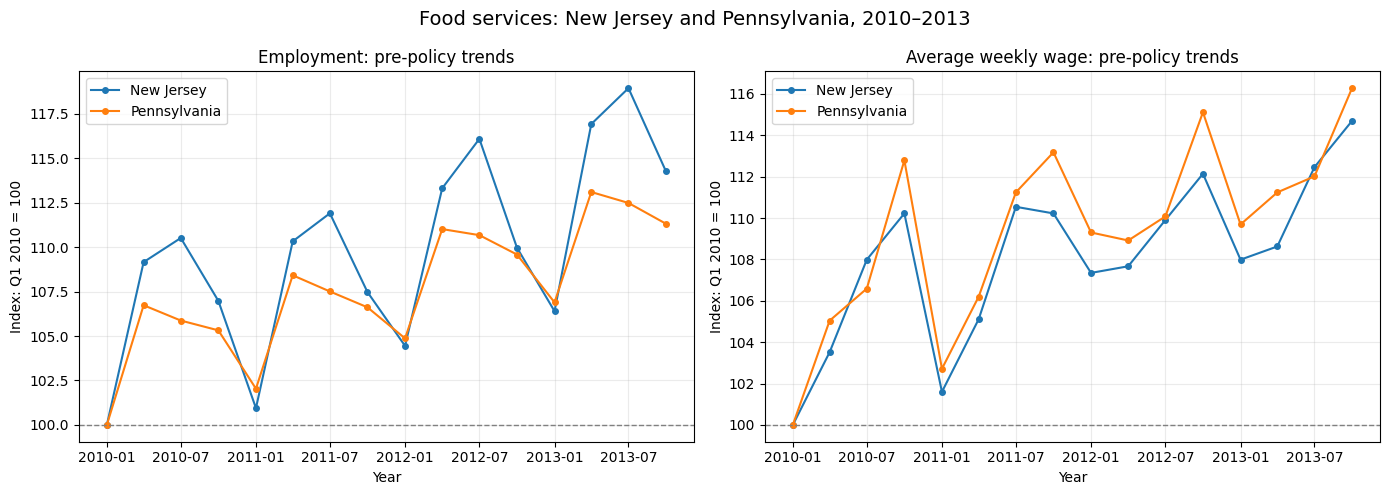

Saved: nj_pa_pre_policy_trends.png


In [ ]:
##Plot pre-policy employment and wage trends
# Use only observations before the January 2014 policy.
pre_policy = comparison.loc[
    comparison["year"] < 2014
].copy()

outcomes = {
    "avg_monthly_employment": "Employment",
    "avg_wkly_wage": "Average weekly wage"
}

# Create one chart for each outcome.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (column, label) in zip(axes, outcomes.items()):

    for state, state_data in pre_policy.groupby("state"):
        # Put observations in chronological order.
        state_data = state_data.sort_values("period")

        # Express each observation relative to that state's Q1 2010 value.
        # Example: 110 means 10% above the starting value.
        baseline = state_data[column].iloc[0]

        if pd.isna(baseline) or baseline <= 0:
            raise ValueError(f"{state}: invalid baseline for {column}.")

        indexed_values = state_data[column] / baseline * 100

        # Convert quarterly periods to dates for plotting.
        dates = state_data["period"].dt.to_timestamp()

        ax.plot(
            dates,
            indexed_values,
            marker="o",
            markersize=4,
            label=state
        )

    ax.set_title(f"{label}: pre-policy trends")
    ax.set_xlabel("Year")
    ax.set_ylabel("Index: Q1 2010 = 100")
    ax.axhline(100, color="gray", linestyle="--", linewidth=1)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(
    "Food services: New Jersey and Pennsylvania, 2010–2013",
    fontsize=14
)
fig.tight_layout()

# Save the chart for our report and GitHub repository.
chart_path = PROJECT_DIR / "outputs" / "nj_pa_pre_policy_trends.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")

plt.show()
print(f"Saved: {chart_path.name}")

In [ ]:
##Compare growth in the same quarter across years
# Compare Q1 observations to reduce the influence of recurring seasonality.
# This is a simple diagnostic, not a parallel-trends test.
q1_trends = pre_policy.loc[
    pre_policy["qtr"].eq(1)
].copy()

# Calculate growth relative to each state's Q1 2010 value.
for column in ["avg_monthly_employment", "avg_wkly_wage"]:
    baseline = q1_trends.groupby("state")[column].transform("first")

    q1_trends[f"{column}_growth_pct"] = (
        (q1_trends[column] / baseline - 1) * 100
    )

# Display comparable growth measures for 2010–2013.
display(
    q1_trends[
        [
            "state",
            "year",
            "avg_monthly_employment_growth_pct",
            "avg_wkly_wage_growth_pct"
        ]
    ].round(2)
)

,state,year,avg_monthly_employment_growth_pct,avg_wkly_wage_growth_pct
0,New Jersey,2010,0.00,0.00
4,New Jersey,2011,0.94,1.60
8,New Jersey,2012,4.45,7.35
12,New Jersey,2013,6.40,7.99
36,Pennsylvania,2010,0.00,0.00
40,Pennsylvania,2011,2.04,2.71
44,Pennsylvania,2012,4.87,9.30
48,Pennsylvania,2013,6.89,9.69


In [ ]:
##Compare year-over-year growth across all pre-policy quarters
# Sort observations so each state's quarters are in chronological order.
pre_growth = pre_policy.sort_values(
    ["state", "period"]
).copy()

# Compare each quarter with the same quarter one year earlier.
# periods=4 means four quarterly observations back.
# This helps account for recurring seasonal patterns.
for column in ["avg_monthly_employment", "avg_wkly_wage"]:
    pre_growth[f"{column}_yoy_pct"] = (
        pre_growth.groupby("state")[column]
        .pct_change(periods=4, fill_method=None)
        * 100
    )

# Arrange the results so the two states appear side by side.
# The first year has no prior-year observations, so exclude it here.
growth_comparison = (
    pre_growth.loc[pre_growth["year"] >= 2011]
    .pivot(
        index="period",
        columns="state",
        values=[
            "avg_monthly_employment_yoy_pct",
            "avg_wkly_wage_yoy_pct"
        ]
    )
)

display(growth_comparison.round(2))

avg_monthly_employment_yoy_pct              avg_wkly_wage_yoy_pct  \
state                      New Jersey Pennsylvania            New Jersey   
period                                                                     
2011Q1                           0.94         2.04                  1.60   
2011Q2                           1.07         1.58                  1.54   
2011Q3                           1.26         1.55                  2.37   
2011Q4                           0.47         1.23                  0.00   
2012Q1                           3.47         2.78                  5.66   
2012Q2                           2.71         2.40                  2.43   
2012Q3                           3.74         2.95                 -0.58   
2012Q4                           2.32         2.79                  1.74   
2013Q1                           1.87         1.93                  0.60   
2013Q2                           3.19         1.88                  0.89   
2013Q3                           2.46         1.64                  2.33   
2013Q4                           3.90         1.58                  2.28   

                     
state  Pennsylvania  
period               
2011Q1         2.71  
2011Q2         1.11  
2011Q3         4.36  
2011Q4         0.34  
2012Q1         6.42  
2012Q2         2.55  
2012Q3        -1.05  
2012Q4         1.71  
2013Q1         0.35  
2013Q2         2.14  
2013Q3         1.76  
2013Q4         1.01

## Preliminary Assessment of Pennsylvania as a Comparison State

### Findings
- From Q1 2010 to Q1 2013, cumulative employment growth was
  similar: 6.40% in New Jersey and 6.89% in Pennsylvania.
- Over the same period, average weekly wages grew 7.99%
  in New Jersey and 9.69% in Pennsylvania.
- Quarterly comparisons reveal differences hidden by those totals.
- In Q4 2013, year-over-year employment growth was 3.90%
  in New Jersey versus 1.58% in Pennsylvania.

### Interpretation
Pennsylvania is a plausible candidate, but these descriptive checks
do not establish parallel trends. Faster New Jersey employment growth
before implementation could bias a simple comparison.

Possible explanations include policy anticipation or other economic
changes. We have not established which explanation applies.

### Analysis decision
Keep Pennsylvania as a benchmark comparison, but do not rely on it
alone for the final causal claim. Investigate additional comparison
states using policy histories and pre-policy outcomes.

Do not choose controls based on whether they produce a statistically
significant or preferred post-policy result.

In [ ]:
# Screen these four candidates using FRED.
# Tennessee is excluded from this download batch pending source verification.
candidate_states = {
    "IN": ("Indiana", "18000"),
    "KS": ("Kansas", "20000"),
    "KY": ("Kentucky", "21000"),
    "VA": ("Virginia", "51000")
}

# Start fresh so rerunning the cell does not duplicate records.
candidate_frames = []

for abbreviation, (state_name, area_code) in candidate_states.items():
    series = f"STTMINWG{abbreviation}"

    raw_path = (
        PROJECT_DIR / "data_raw"
        / f"fred_{abbreviation.lower()}_minimum_wage.csv"
    )

    # Reuse the files already downloaded before the Tennessee error.
    if raw_path.exists():
        print(f"{state_name}: reading saved file.")
        raw = pd.read_csv(raw_path, na_values=["."])

    else:
        print(f"{state_name}: downloading...", flush=True)

        url = (
            f"https://fred.stlouisfed.org/graph/"
            f"fredgraph.csv?id={series}"
        )
        response = requests.get(url, timeout=60)
        response.raise_for_status()

        raw = pd.read_csv(
            BytesIO(response.content),
            na_values=["."]
        )

        # Check the response before saving it.
        if series not in raw.columns:
            raise ValueError(f"{state_name}: expected series not returned.")

        raw_path.write_bytes(response.content)

    # Validate saved files as well as new downloads.
    if series not in raw.columns:
        raise ValueError(f"{state_name}: expected series is missing.")

    # Extract the observation year and numeric wage rate.
    date_column = raw.columns[0]
    raw["year"] = pd.to_datetime(
        raw[date_column], errors="raise"
    ).dt.year

    raw["state_min_wage"] = pd.to_numeric(
        raw[series], errors="raise"
    )

    # Keep the nine years matching our employment panel.
    selected = raw.loc[
        raw["year"].between(2010, 2018),
        ["year", "state_min_wage"]
    ].copy()

    if (
        selected["year"].duplicated().any()
        or set(selected["year"]) != set(range(2010, 2019))
    ):
        raise ValueError(f"{state_name}: year coverage needs review.")

    # Attach identifiers for later matching to employment data.
    selected["state"] = state_name
    selected["area_fips"] = area_code
    candidate_frames.append(selected)

# Combine only the four successfully processed candidate histories.
candidate_wages = pd.concat(candidate_frames, ignore_index=True)

display(
    candidate_wages.pivot(
        index="year",
        columns="state",
        values="state_min_wage"
    )
)

print("\nMissing wage values by state:")
print(
    candidate_wages.groupby("state")["state_min_wage"]
    .apply(lambda values: values.isna().sum())
)

Indiana: reading saved file.
Kansas: reading saved file.
Kentucky: reading saved file.
Virginia: downloading...


state,Indiana,Kansas,Kentucky,Virginia
year,,,,
2010,7.25,7.25,7.25,7.25
2011,7.25,7.25,7.25,7.25
2012,7.25,7.25,7.25,7.25
2013,7.25,7.25,7.25,7.25
2014,7.25,7.25,7.25,7.25
2015,7.25,7.25,7.25,7.25
2016,7.25,7.25,7.25,7.25
2017,7.25,7.25,7.25,7.25
2018,7.25,7.25,7.25,7.25



Missing wage values by state:
state
Indiana     0
Kansas      0
Kentucky    0
Virginia    0
Name: state_min_wage, dtype: int64


In [ ]:
##Build a pre-policy comparison table for all candidates
# Include New Jersey, Pennsylvania, and the four additional candidates.
state_names = {
    "34000": "New Jersey",
    "42000": "Pennsylvania",
    "18000": "Indiana",
    "20000": "Kansas",
    "21000": "Kentucky",
    "51000": "Virginia"
}

# Use only pre-policy observations so screening does not depend
# on the estimated post-policy results.
screening_data = panel.loc[
    panel["area_fips"].isin(state_names)
    & panel["year"].between(2010, 2013)
].copy()

screening_data["state"] = screening_data["area_fips"].map(state_names)

# Average the four quarterly observations within each state and year.
# Weekly wages here are a simple average of quarterly averages,
# not an employment-weighted annual wage measure.
annual_pre = (
    screening_data.groupby(["state", "year"])[
        ["avg_monthly_employment", "avg_wkly_wage"]
    ]
    .mean()
    .reset_index()
    .sort_values(["state", "year"])
)

# Express changes relative to each state's 2010 annual average.
for column in ["avg_monthly_employment", "avg_wkly_wage"]:
    baseline = annual_pre.groupby("state")[column].transform("first")

    annual_pre[f"{column}_growth_pct"] = (
        annual_pre[column] / baseline - 1
    ) * 100

# Display every pre-policy year, not just the final growth difference.
display(
    annual_pre[
        [
            "state", "year",
            "avg_monthly_employment_growth_pct",
            "avg_wkly_wage_growth_pct"
        ]
    ].round(2)
)

# Save the screening table for documentation.
screening_path = (
    PROJECT_DIR / "data_processed"
    / "candidate_states_pre_policy_growth_2010_2013.csv"
)
annual_pre.to_csv(screening_path, index=False)

,state,year,avg_monthly_employment_growth_pct,avg_wkly_wage_growth_pct
0,Indiana,2010,0.00,0.00
1,Indiana,2011,1.91,1.40
2,Indiana,2012,5.15,4.20
3,Indiana,2013,7.46,4.50
4,Kansas,2010,0.00,0.00
5,Kansas,2011,1.08,1.74
6,Kansas,2012,4.03,4.49
7,Kansas,2013,5.21,6.23
8,Kentucky,2010,0.00,0.00
9,Kentucky,2011,1.67,1.36


In [ ]:
#Check the pooled benchmark’s pre-policy growth
# Use all five screened candidates with equal weights.
# This is an exploratory benchmark, not a finalized control group.
control_names = [
    "Pennsylvania", "Indiana", "Kansas", "Kentucky", "Virginia"
]

growth_columns = [
    "avg_monthly_employment_growth_pct",
    "avg_wkly_wage_growth_pct"
]

# Average the states' growth percentages within each pre-policy year.
# Each state receives the same weight, regardless of its size.
pooled_growth = (
    annual_pre.loc[annual_pre["state"].isin(control_names)]
    .groupby("year")[growth_columns]
    .mean()
    .add_prefix("controls_")
)

# Extract New Jersey's growth for the same years.
nj_growth = (
    annual_pre.loc[annual_pre["state"].eq("New Jersey")]
    .set_index("year")[growth_columns]
    .add_prefix("nj_")
)

# Join the two tables by year.
pooled_check = nj_growth.join(pooled_growth, validate="one_to_one")

# Calculate New Jersey minus the pooled controls.
# These gaps are measured in percentage points.
pooled_check["employment_gap_pp"] = (
    pooled_check["nj_avg_monthly_employment_growth_pct"]
    - pooled_check["controls_avg_monthly_employment_growth_pct"]
)

pooled_check["wage_gap_pp"] = (
    pooled_check["nj_avg_wkly_wage_growth_pct"]
    - pooled_check["controls_avg_wkly_wage_growth_pct"]
)

display(pooled_check.round(2))

,nj_avg_monthly_employment_growth_pct,nj_avg_wkly_wage_growth_pct,controls_avg_monthly_employment_growth_pct,controls_avg_wkly_wage_growth_pct,employment_gap_pp,wage_gap_pp
year,,,,,,
2010,0.00,0.00,0.00,0.00,0.00,0.00
2011,0.94,1.36,1.82,1.62,-0.88,-0.26
2012,4.03,3.64,4.91,4.21,-0.88,-0.57
2013,7.00,5.23,7.03,5.00,-0.03,0.23


##Document our comparison strategy
## Comparison Strategy: Preliminary Decision

### Candidate states
Pennsylvania, Indiana, Kansas, Kentucky, and Virginia.

Their downloaded annual minimum wage series show $7.25 throughout
2010–2018. Exact policy histories, coverage rules, and relevant
state/local policy changes still require verification.

### Pre-policy findings
Compared with an equal-weight average of these five states:
- New Jersey's employment growth was 0.88 percentage points lower
  in both 2011 and 2012.
- By 2013, the cumulative employment growth gap was −0.03
  percentage points.
- The cumulative weekly wage growth gap was +0.23 percentage
  points in 2013.

### Interpretation
The pooled benchmark has similar cumulative growth by 2013,
but the path differs. We cannot conclude that parallel trends hold.

### Planned comparisons
1. New Jersey versus Pennsylvania.
2. New Jersey versus the five-state pooled benchmark.
3. Leave-one-control-state-out sensitivity checks.

These are provisional specifications. We will examine quarterly
pre-policy patterns and policy context before finalizing the design.

### Statistical limitation
There is only one treated state and five candidate control states.
Ordinary standard errors or conventional clustering with so few
states may give misleading confidence intervals and p-values.
Inference will need explicit small-sample limitations and carefully
chosen robustness checks.

In [ ]:
##Save the candidate wage histories
# Add Pennsylvania to the four other candidate-state wage histories.
pa_candidate = pa_wage.assign(
    state="Pennsylvania",
    area_fips="42000"
)

control_policy = pd.concat(
    [
        candidate_wages[
            ["state", "area_fips", "year", "state_min_wage"]
        ],
        pa_candidate[
            ["state", "area_fips", "year", "state_min_wage"]
        ]
    ],
    ignore_index=True
)

# Each candidate should have one observation per study year.
expected_keys = {
    (area, year)
    for area in ["42000", "18000", "20000", "21000", "51000"]
    for year in range(2010, 2019)
}

actual_keys = set(
    control_policy[["area_fips", "year"]]
    .itertuples(index=False, name=None)
)

# Stop if records are duplicated, incomplete, or missing wage values.
if (
    control_policy.duplicated(["area_fips", "year"]).any()
    or actual_keys != expected_keys
    or control_policy["state_min_wage"].isna().any()
):
    raise ValueError("Candidate policy coverage needs review.")

# Sort and save the annual policy screening data.
control_policy = control_policy.sort_values(
    ["state", "year"]
).reset_index(drop=True)

control_policy_path = (
    PROJECT_DIR / "data_processed"
    / "candidate_states_annual_minimum_wage_2010_2018.csv"
)
control_policy.to_csv(control_policy_path, index=False)

# Save the pooled pre-policy diagnostic as well.
pooled_check_path = (
    PROJECT_DIR / "outputs" / "pooled_pre_policy_growth_check.csv"
)
pooled_check.to_csv(pooled_check_path, index=True)

print("Candidate policy records:", len(control_policy))
print("Candidate states:", control_policy["state"].nunique())
print("Saved both policy histories and pooled growth diagnostic.")

Candidate policy records: 45
Candidate states: 5
Saved both policy histories and pooled growth diagnostic.


##Record these dates and planned sensitivity checks
## Policy Timeline and Potential Confounding

### November 5, 2013: Minimum wage amendment approved
Voters approved the increase before its January 2014 implementation.
Employers may have adjusted hiring or pay in anticipation.

Approval does not establish when anticipation began. Earlier public
discussion may also have influenced decisions.

### January 1, 2014: Minimum wage increase implemented
The general state minimum wage increased from $7.25 to $8.25.
Subsequent inflation adjustments are part of the policy path studied.

### October 29, 2018: Statewide earned sick leave law implemented
This separate labor policy could affect employment or compensation.
Its effects cannot automatically be attributed to the minimum wage.

### Planned sensitivity checks
- Exclude Q4 2013 as a possible anticipation period.
- Compare results ending in 2017 with results through 2018.
- Examine quarterly pre-policy patterns and other state/local policies.

These checks will assess sensitivity, not eliminate all confounding.
The downloaded 2010–2018 panel will remain unchanged.

### Sources
- Approval date:
  https://www.njleg.state.nj.us/bill-search/2014/A2736/bill-text?f=A3000&n=2736_I1
  Historical statement within a proposed bill; not evidence that
  the proposed bill itself became law.
- Implementation:
  https://www.nj.gov/agriculture/about/convention/2014/stateminimumwage.shtml
- Earned sick leave:
  https://www.nj.gov/labor/earnedsickleave/